   rho  effective_sample_size  empirical_type1_error  asymptotic_type1_error
0 -0.5               300.0000                 0.0005                  0.0007
1  0.0               100.0000                 0.0519                  0.0500
2  0.5                33.3333                 0.2638                  0.2578


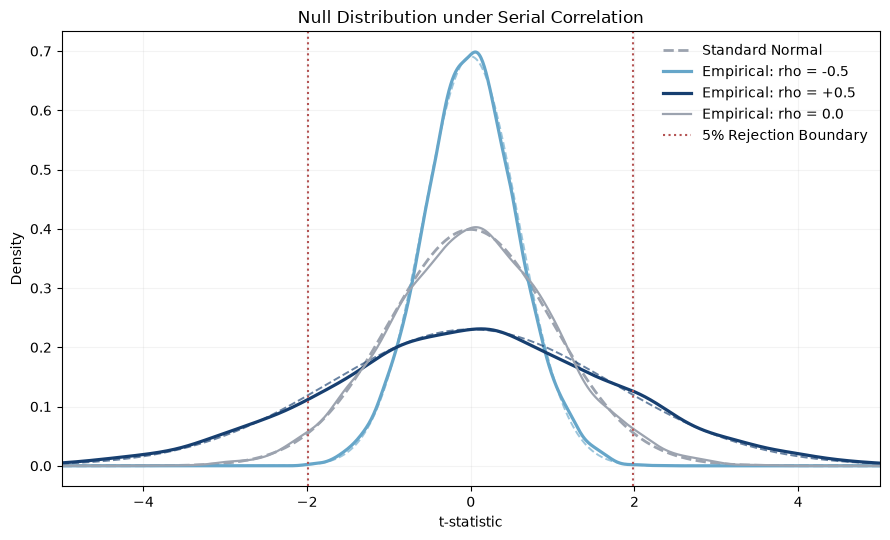

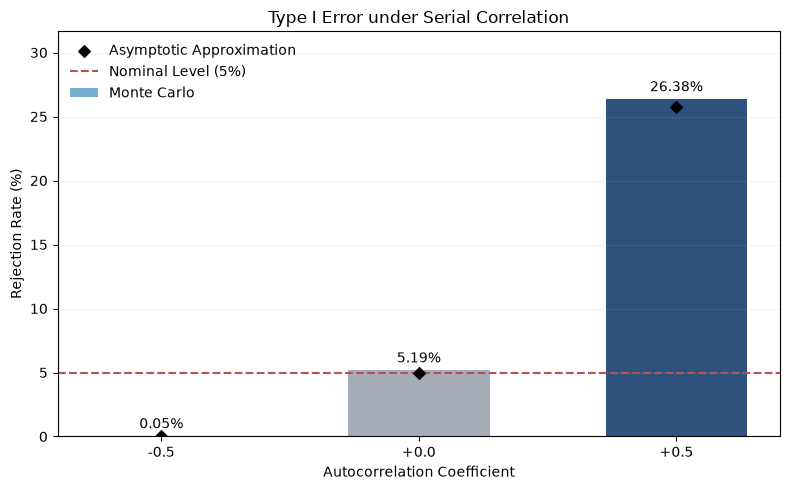

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# --------------------------------------------------
# 1. Simulation settings
# --------------------------------------------------
N = 100
N_SIM = 10_000
RHOS = [-0.5, 0.0, 0.5]
ALPHA = 0.05
SEED = 42

COLORS = {
    -0.5: "#66A6C9",  # Negative autocorrelation
     0.0: "#9CA3AF",  # Independence
     0.5: "#173F70",  # Positive autocorrelation
}

rng = np.random.default_rng(SEED)


# --------------------------------------------------
# 2. Generate stationary AR(1) samples
# --------------------------------------------------
def simulate_ar1(rho, n, n_sim, rng):
    """
    Y_t = rho * Y_(t-1) + epsilon_t

    E[Y_t] = 0
    Var(Y_t) = 1
    Corr(Y_t, Y_(t-k)) = rho**k
    """
    y = np.empty((n_sim, n))

    # Initialize from stationary distribution
    y[:, 0] = rng.normal(0, 1, size=n_sim)

    # Innovation variance = 1 - rho**2
    innovations = rng.normal(
        0, np.sqrt(1 - rho**2), size=(n_sim, n - 1)
    )

    for t in range(1, n):
        y[:, t] = rho * y[:, t - 1] + innovations[:, t - 1]

    return y


# --------------------------------------------------
# 3. Monte Carlo experiment
# --------------------------------------------------
results = []
t_statistics = {}

for rho in RHOS:
    y = simulate_ar1(rho, N, N_SIM, rng)

    sample_mean = y.mean(axis=1)
    sample_std = y.std(axis=1, ddof=1)

    # Conventional SE, ignoring serial correlation
    se_naive = sample_std / np.sqrt(N)

    t_stat = sample_mean / se_naive
    p_value = 2 * stats.t.sf(np.abs(t_stat), df=N - 1)

    rejection_rate = np.mean(p_value < ALPHA)

    # Asymptotic rejection probability
    tau = (1 + rho) / (1 - rho)
    critical = stats.norm.ppf(1 - ALPHA / 2)
    theoretical_rate = 2 * stats.norm.sf(
        critical / np.sqrt(tau)
    )

    results.append({
        "rho": rho,
        "effective_sample_size": N / tau,
        "empirical_type1_error": rejection_rate,
        "asymptotic_type1_error": theoretical_rate
    })

    t_statistics[rho] = t_stat

result_df = pd.DataFrame(results)

print(result_df.round(4))


# --------------------------------------------------
# 4. Plot: Null distribution of t-statistics
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.linspace(-5, 5, 1000)

# Standard normal reference
ax.plot(
    x,
    stats.norm.pdf(x),
    color="#9CA3AF",
    linestyle="--",
    linewidth=2,
    label="Standard Normal"
)

for rho in RHOS:
    if rho == 0:
        continue

    # Theoretical asymptotic density
    tau = (1 + rho) / (1 - rho)

    ax.plot(
        x,
        stats.norm.pdf(x, scale=np.sqrt(tau)),
        color=COLORS[rho],
        linestyle="--",
        linewidth=1.4,
        alpha=0.65
    )

    # Empirical Monte Carlo density
    kde = stats.gaussian_kde(t_statistics[rho])

    ax.plot(
        x,
        kde(x),
        color=COLORS[rho],
        linewidth=2.3,
        label=f"Empirical: rho = {rho:+.1f}"
    )

# Empirical density under independence
kde_ind = stats.gaussian_kde(t_statistics[0.0])

ax.plot(
    x,
    kde_ind(x),
    color=COLORS[0.0],
    linewidth=1.6,
    label="Empirical: rho = 0.0"
)

critical_t = stats.t.ppf(1 - ALPHA / 2, df=N - 1)

ax.axvline(
    -critical_t, color="#B45353",
    linestyle=":", linewidth=1.5
)
ax.axvline(
    critical_t, color="#B45353",
    linestyle=":", linewidth=1.5,
    label="5% Rejection Boundary"
)

ax.set(
    title="Null Distribution under Serial Correlation",
    xlabel="t-statistic",
    ylabel="Density",
    xlim=(-5, 5)
)

ax.legend(frameon=False)
ax.grid(alpha=0.15)

plt.tight_layout()
plt.savefig("null_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 5. Plot: Empirical Type I Error
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

x_pos = np.arange(len(RHOS))

empirical = result_df["empirical_type1_error"].to_numpy() * 100
theoretical = result_df["asymptotic_type1_error"].to_numpy() * 100

bars = ax.bar(
    x_pos,
    empirical,
    width=0.55,
    color=[COLORS[rho] for rho in RHOS],
    alpha=0.9,
    label="Monte Carlo"
)

ax.scatter(
    x_pos,
    theoretical,
    color="black",
    marker="D",
    s=35,
    zorder=3,
    label="Asymptotic Approximation"
)

ax.axhline(
    ALPHA * 100,
    color="#B45353",
    linestyle="--",
    linewidth=1.5,
    label="Nominal Level (5%)"
)

for bar, value in zip(bars, empirical):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{value:.2f}%",
        ha="center",
        fontsize=10
    )

ax.set(
    title="Type I Error under Serial Correlation",
    xlabel="Autocorrelation Coefficient",
    ylabel="Rejection Rate (%)",
    xticks=x_pos,
    xticklabels=[f"{rho:+.1f}" for rho in RHOS]
)

ax.set_ylim(0, max(empirical.max(), theoretical.max()) * 1.2)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.15)

plt.tight_layout()
plt.savefig("type1_error.png", dpi=300, bbox_inches="tight")
plt.show()
